# Multilevel Monte Carlo for a cantilever beam

Fred J. Hickernell · MATH 565, Fall 2026

Companion to [Selected Topics: Multilevel Monte Carlo](https://fjhickernell.github.io/MATH565Fall2026/slides/05-selected-topics.html#multilevel-monte-carlo).

A beam with uncertain stiffness gives a small example of **coupling**, **sample allocation**, and **approximation bias**. Use the existing course `qmcpy` kernel and Run All. The forward model runs directly in Python; no Docker, server, or additional model software is needed.

This is a classroom adaptation of the [UM-Bridge cantilever-beam benchmark](https://um-bridge-benchmarks.readthedocs.io/en/docs/forward-benchmarks/muq-beam-propagation.html) used in QMCPy's `umbridge.ipynb`. We generalize the benchmark to a configurable number of independently uncertain material regions. The default uses 16 regions and log stiffnesses uniform on $[0,2]$, giving substantially more variability than the original narrow three-region example. We explicitly choose unit length, unit uniform load, and tip displacement as the output. We use midpoint integration instead of the container's finite-difference solver and load/geometry data. An exact solution makes the remaining bias measurable.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fjhickernell/MATH565Fall2026/blob/main/notebooks/performance/MultilevelBeam.ipynb)

The parameter cell controls the problem size and work budget. The default is intended as a substantive classroom run; reduce `WORK_BUDGET` for a quick check, or increase it for a longer experiment. Doubling this budget approximately doubles final-sample work. `TRIALS` controls how many whole estimates are repeated to measure RMSE; it is separate from the budget for one estimate. Absolute RMSE depends on the output scale. The main comparison also reports RMSE as a percentage of the target mean, so accuracy can be interpreted relative to the size of the answer.

In [1]:
from pathlib import Path
import subprocess
import sys
import time

NOTEBOOK_START_TIME = time.perf_counter()

colab = "google.colab" in sys.modules
if colab:
    print("Setting up this course's recorded classlib and QMCPy; this may take several minutes …")
    course_checkout = Path("/content/MATH565Fall2026")
    if not course_checkout.exists():
        subprocess.run(
            [
                "git", "clone", "--quiet", "--depth", "1",
                "https://github.com/fjhickernell/MATH565Fall2026.git",
                str(course_checkout),
            ],
            check=True,
        )
    subprocess.run(
        [
            "git", "-C", str(course_checkout),
            "-c", "submodule.classlib.url=https://github.com/fjhickernell/HickernellAcademicLib.git",
            "-c", "submodule.qmcpy.url=https://github.com/QMCSoftware/qmcpy.git",
            "submodule", "update", "--init", "classlib", "qmcpy",
        ],
        check=True,
    )
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "-q",
            str(course_checkout / "classlib"),
            str(course_checkout / "qmcpy"),
        ],
        check=True,
    )
    print("Colab setup complete.")
    print("For faster repeated work, use the local `qmcpy` environment.")

In [2]:
search_start = course_checkout if colab else Path.cwd().resolve()
course_root = next((p for p in [search_start, *search_start.parents]
                    if (p / 'course-metadata.yml').is_file()
                    and (p / 'qmcpy/qmcpy').is_dir()), None)
if course_root is None:
    raise RuntimeError('Run from the course checkout or use the Colab setup.')
for folder in ['notebooks', 'classlib', 'qmcpy']:
    sys.path.insert(0, str(course_root / folder))

from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import qmcpy as qp
import classlib as cl
from beam_mlmc import (beam_tip, beam_profile, exact_tip, reference_moments,
                       level_moments, compliance_moments, BeamMultilevel)

%matplotlib inline
cl.nbviz.init(use_tex=False)
pd.options.display.float_format = lambda value: f'{value:.6g}'

SEED = 5651104
L = 5                         # Levels 1,...,L
REGIONS = 16                  # Independent material parameters
LOWER, UPPER = 0.0, 2.0        # Uniform log stiffness: E is between exp(LOWER) and exp(UPPER)
PILOT_N = 256
WORK_BUDGET = 2**25             # Panel-evaluation proxy, including allocation pilot
TRIALS = 24                    # Independent whole-estimator repetitions
BATCH = 4096
levels = np.arange(1, L+1)
panels = REGIONS * 2**(levels-1)
proxy_cost = panels + np.r_[0, panels[:-1]]
# Bind every analytic check to the same material distribution as the simulation.
reference_moments = partial(reference_moments, lower=LOWER, upper=UPPER, regions=REGIONS)
level_moments = partial(level_moments, lower=LOWER, upper=UPPER, regions=REGIONS)
compliance_moments = partial(compliance_moments, lower=LOWER, upper=UPPER)
assert L>=3 and REGIONS>=1 and WORK_BUDGET>0
assert WORK_BUDGET>PILOT_N*proxy_cost.sum(), 'WORK_BUDGET must cover the allocation pilot'
mu, _ = reference_moments()
mu_fine, variance_fine = reference_moments(int(panels[-1]))
bias = mu-mu_fine

def stream(*labels):
    return np.random.SeedSequence([SEED, *labels])

def material(seed):
    return qp.Uniform(qp.IIDStdUniform(REGIONS, seed=seed), lower_bound=LOWER, upper_bound=UPPER)

print(f'QMCPy {qp.__version__}; {REGIONS} independent material regions; {L} levels; {panels[-1]} finest panels')
print(f'Exact limiting mean: {mu:.10f}; finite-grid mean: {mu_fine:.10f}; bias: {bias:.3g}')

QMCPy 2.4; 16 independent material regions; 5 levels; 256 finest panels
Exact limiting mean: 0.0540415448; finite-grid mean: 0.0540411325; bias: 4.12e-07


## 1. One beam, increasingly fine grids

Let $q=\texttt{REGIONS}$, $a=\texttt{LOWER}$, and $b=\texttt{UPPER}$. Generate $\boldsymbol U\sim\operatorname{Unif}([0,1]^q)$ and $\boldsymbol X=a+(b-a)\boldsymbol U$. On region $j$, the effective stiffness is $e^{X_j}$. The default has 16 independently varying regions, with stiffnesses between $e^0=1$ and $e^2\approx7.39$. This wider uncertainty makes sampling accuracy more demanding without changing the load just to rescale the answer.

With positive downward deflection, a unit uniform load gives
\begin{align*}
\bigl(E(x)u''(x)\bigr)''&=1, &u(0)&=u'(0)=0,\\
(Eu'')(1)&=(Eu'')'(1)=0, &E(x)u''(x)&=(1-x)^2/2.
\end{align*}
Two integrations give the tip deflection
$$
P(\boldsymbol X)=u(1)=\int_0^1\frac{(1-x)^3}{2E(x)}\,\mathrm dx.
$$
The simulation approximates this integral on $d_\ell=q\,2^{\ell-1}$ midpoint panels. Every grid respects the material interfaces. $P_{d_\ell}$ is the resulting approximation.

Here **grid resolution increases while the random input dimension stays $q$**. The small model is deliberately easy to validate; it is not a performance model for a large finite-element solver. The functions in [`beam_mlmc.py`](../beam_mlmc.py) evaluate all panels for each simulated beam; the exact formulas are used only as references.

### Reading the beam picture

Each color is one sample of the **entire material field**, containing `REGIONS` independent parameters. It is not a mesh level. The left panel shows the stiffness on the material regions. On the right, the solid curve uses the finest grid and the dots use one quarter as many panels for the **same material sample**, a four-to-one illustration. The table below compares their tip deflections. The five-level MLMC experiment that follows uses factor-two refinement.


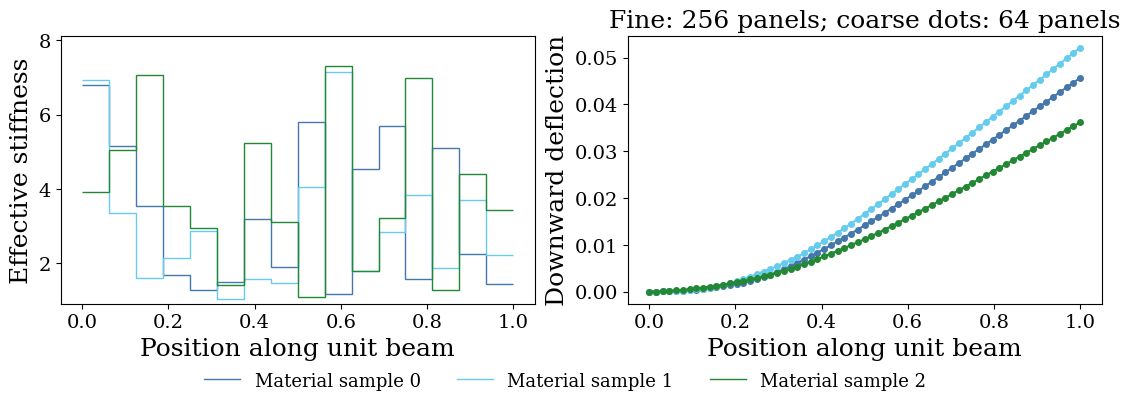

,coarse_tip,fine_tip,correction
sample,,,
0,0.0456667,0.0456726,5.88532e-06
1,0.0521108,0.0521172,6.40324e-06
2,0.0361506,0.0361555,4.85736e-06


In [3]:
m_demo = material(stream(1))(3)
fine_demo = int(panels[-1])
coarse_demo = fine_demo//4
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for j, m in enumerate(m_demo):
    axes[0].stairs(np.exp(m), np.arange(REGIONS+1)/REGIONS, baseline=None, label=f'Material sample {j}')
    x, u = beam_profile(m, fine_demo)
    line, = axes[1].plot(x, u, label=f'Fine beam {j}')
    xc, uc = beam_profile(m, coarse_demo)
    axes[1].plot(xc, uc, 'o', color=line.get_color(), markersize=4)
axes[0].set(xlabel='Position along unit beam', ylabel='Effective stiffness', ylim=(.9*np.exp(LOWER), 1.1*np.exp(UPPER)))
axes[1].set(xlabel='Position along unit beam', ylabel='Downward deflection',
            title=f'Fine: {fine_demo} panels; coarse dots: {coarse_demo} panels')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3, fontsize=13)
plt.show()
coarse_tips, fine_tips = beam_tip(m_demo, coarse_demo), beam_tip(m_demo, fine_demo)
display(pd.DataFrame({'sample':np.arange(len(m_demo)), 'coarse_tip':coarse_tips,
                      'fine_tip':fine_tips, 'correction':fine_tips-coarse_tips}).set_index('sample'))

## 2. Coupling means using the same material sample

Use the **same material-parameter vector** for both solves in each correction:
\begin{align*}
Y_1&=P_{d_1}(\boldsymbol X),\\
Y_\ell&=P_{d_\ell}(\boldsymbol X)-P_{d_{\ell-1}}(\boldsymbol X),\qquad\ell\ge2.
\end{align*}
The expectations telescope to $\mu_{d_L}=\mathbb E(P_{d_L})$. Using unrelated materials for the two solves preserves the mean difference but loses the covariance that reduces its variance. **Different level means use independent sample sets.**

The work proxy is $\$_1=d_1$ and $\$_\ell=d_\ell+d_{\ell-1}$ for a correction. It counts evaluated panels, not seconds. Complete timings also include QMCPy generation, transformation, and Python overhead.

### What the levels mean

A **level is a grid resolution**, not a material parameter or a sample count. The grid starts with one panel per material region and doubles its panels at each refinement. The generated level-guide table below shows the actual fine and coarse grids from the current settings.

Each row uses `PILOT_N` samples. One work unit is one evaluated quadrature panel. This is a proxy for computational effort, not a clock-time measurement or an exact CPU-operation count. A single-level sample evaluates only the finest payoff; a correction evaluates both fine and coarse payoffs.


**Level guide** — the base payoff has no coarse evaluation.

,fine_panels,coarse_panels,sampled_contribution,proxy_cost
level,,,,
1,16,0,base payoff,16
2,32,16,fine minus coarse,48
3,64,32,fine minus coarse,96
4,128,64,fine minus coarse,192
5,256,128,fine minus coarse,384


**Pilot measurements**

,panels,correction_mean,coupled_variance,independent_variance,proxy_cost,complete_batch_seconds,seconds_per_contribution
level,,,,,,,
1,16,0.0543258,0.000157067,0.000134964,16,0.000745458,2.91195e-06
2,32,7.96912e-05,1.50266e-10,0.000261618,48,0.000323125,1.26221e-06
3,64,1.96662e-05,8.94153e-12,0.000265205,96,0.000203,7.92969e-07
4,128,4.89532e-06,7.34852e-13,0.000236604,192,0.000251292,9.81609e-07
5,256,1.2159e-06,3.67687e-14,0.000268585,384,0.000275834,1.07748e-06


Allocation pilot: 188,416 proxy work; independent-difference diagnostics are separate teaching work


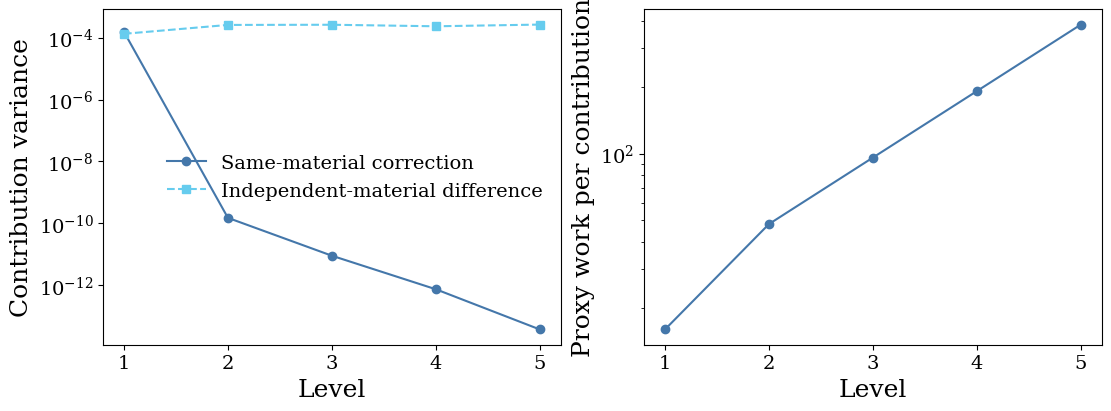

In [4]:
def values(ell, n, seed, correction=True):
    d = int(REGIONS*2**(int(ell)-1))
    def output(m):
        fine = beam_tip(m, d)
        return fine-beam_tip(m, d//2) if correction and ell>1 else fine
    integrand = qp.CustomFun(material(seed), g=output)
    return np.concatenate([integrand(n_min=start, n_max=min(start+BATCH, n), warn=False)
                           for start in range(0, int(n), BATCH)])

pilot_rows = []
for ell, d, c in zip(levels, panels, proxy_cost):
    started = time.perf_counter()
    coupled = values(ell, PILOT_N, stream(2, int(ell)))
    seconds = time.perf_counter()-started
    direct = values(ell, PILOT_N, stream(3, int(ell)), correction=False)
    independent_variance = direct.var(ddof=1)
    if ell>1:
        coarse = values(ell-1, PILOT_N, stream(4, int(ell)), correction=False)
        independent_variance += coarse.var(ddof=1)
    pilot_rows.append(dict(level=ell, panels=d, correction_mean=coupled.mean(),
                           coupled_variance=coupled.var(ddof=1),
                           independent_variance=independent_variance,
                           proxy_cost=c, complete_batch_seconds=seconds,
                           seconds_per_contribution=seconds/PILOT_N))
pilot = pd.DataFrame(pilot_rows).set_index('level')
V_hat = pilot.coupled_variance.to_numpy()
V_exact = np.array([level_moments(int(ell))[1] for ell in levels])
PILOT_WORK = int(PILOT_N*proxy_cost.sum())
PILOT_SECONDS = float(pilot.complete_batch_seconds.sum())
direct_fine_pilot_variance = float(direct.var(ddof=1))
level_guide = pd.DataFrame({'fine_panels':panels,'coarse_panels':np.r_[0,panels[:-1]],
    'sampled_contribution':['base payoff']+['fine minus coarse']*(L-1),
    'proxy_cost':proxy_cost},index=levels).rename_axis('level')
display(Markdown('**Level guide** — the base payoff has no coarse evaluation.'))
display(level_guide)
display(Markdown('**Pilot measurements**'))
display(pilot)
print(f'Allocation pilot: {PILOT_WORK:,} proxy work; independent-difference diagnostics are separate teaching work')
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].semilogy(levels, V_hat, 'o-', label='Same-material correction')
axes[0].semilogy(levels, pilot.independent_variance, 's--', label='Independent-material difference')
axes[0].set(xlabel='Level', ylabel='Contribution variance', xticks=levels)
axes[1].semilogy(levels, proxy_cost, 'o-')
axes[1].set(xlabel='Level', ylabel='Proxy work per contribution', xticks=levels)
axes[0].legend()
plt.show()

### Reading the pilot table and the two plots

| Column | Meaning |
|:---|:---|
| `panels` | Fine-grid quadrature panels for this level |
| `correction_mean` | Pilot estimate of $\mathbb E(Y_\ell)$; level 1 is the coarse payoff itself |
| `coupled_variance` | Pilot estimate of $V_\ell$ for **one** shared-material contribution |
| `independent_variance` | Estimated variance if fine and coarse material samples were independent; their payoff variances add |
| `proxy_cost` | Fine panels plus coarse panels for a correction, or just the base panels |
| `complete_batch_seconds` | Measured time to construct, generate, transform, and evaluate the coupled pilot batch |
| `seconds_per_contribution` | That time divided by the pilot count |

At the finest level, evaluate the same material field on the two grids listed in the level guide. Its `proxy_cost` includes both evaluations. Its coupled variance is much smaller than the independent-material variance. These are **one-contribution variances**; the variance of an $n_\ell$-sample level mean is $V_\ell/n_\ell$.

**Left plot:** contribution variance falls rapidly when fine and coarse beams share materials; independent-material differences retain large variance. At level 1, both curves estimate the base-payoff variance from different samples, so they need not coincide. **Right plot:** contributions become more expensive as grids get finer. This tradeoff determines the sample allocation in Part 3.

The correction mean is a grid-to-grid change, not the remaining bias to infinite resolution. Measured seconds need not grow exactly like the panel proxy because small-batch setup and vectorization matter. Independent-difference diagnostics are separate teaching work; only the coupled pilot is used to select the allocation.

## 3. Allocate points and account for their work

For independent IID level means,
$$
\operatorname{var}(\widehat\mu)=\sum_{\ell=1}^L V_\ell/n_\ell,
\qquad
w_\ell=\sqrt{V_\ell/\$_\ell},
\qquad
n_\ell=\frac{Cw_\ell}{\sum_{k=1}^L\$_kw_k}.
$$

Compare equal point counts, equal work per level, the pilot-based optimum, and **single-level IID on the same finest grid**. Every design receives the same maximum `WORK_BUDGET`, with

$$
\texttt{total\_work}=\texttt{final\_work}+\texttt{pilot\_work}.
$$

`final_work` pays for the final samples used in the estimate. `pilot_work` pays for the discarded samples used to choose the optimal allocation. `total_work` adds these charges; `unused_work` is the budget left after rounding. These are **panel-work proxy units**, not seconds. The optimum's pilot is deducted before its final samples are allocated. The other three designs require no allocation pilot.

A single-level sample needs only the finest payoff: it costs the number of finest-grid panels. A correction also evaluates the previous grid, so its `proxy_cost` is larger. The single-level bars therefore appear only at the finest level.

The first table reports point counts. The second reports work accounting and **predicted sampling RMSE as a percentage of the fixed finest-grid mean**. Predictions use the variance diagnostics from Part 2; the allocation uses pilot estimates, not analytic variances. The fine-payoff variance diagnostic assesses the single-level design but does not choose its sample count, so it is separate teaching work.


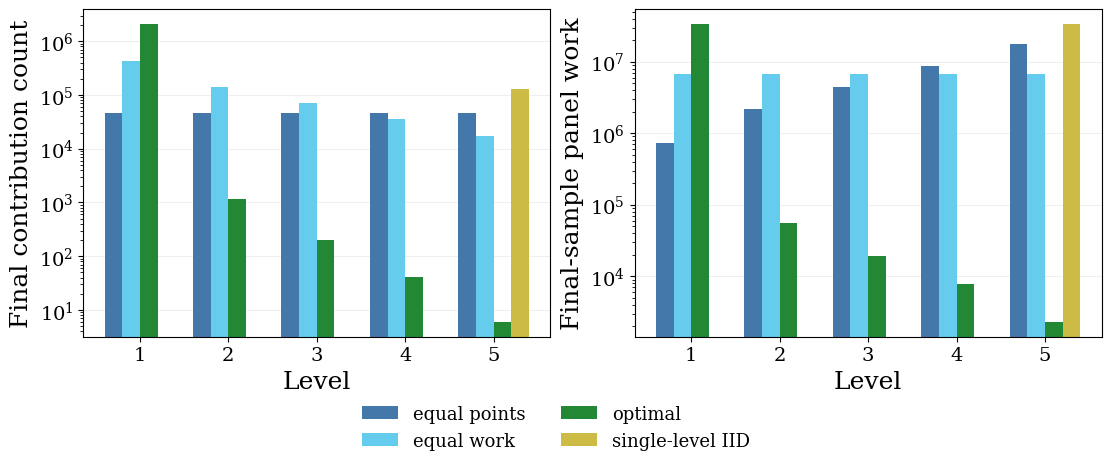

,panels,cost_per_contribution,equal points,equal work,optimal,single-level IID
level,,,,,,
1,16,16,45590,419430,2079987,0
2,32,48,45590,139810,1174,0
3,64,96,45590,69905,202,0
4,128,192,45590,34952,41,0
5,256,384,45590,17476,6,131072


Maximum total-work budget for every design: 33,554,432 evaluated-panel units


,final_work,pilot_work,total_work,unused_work,predicted_sampling_RMSE_percent
design,,,,,
equal points,33554240,0,33554240,192,0.108614
equal work,33554208,0,33554208,224,0.0358088
optimal,33365712,188416,33554128,304,0.016101
single-level IID,33554432,0,33554432,0,0.0625996


In [5]:
def allocation(budget, kind='optimal'):
    if kind=='equal points':
        weights = np.ones(L)
    elif kind=='equal work':
        weights = 1/proxy_cost
    else:
        weights = np.sqrt(V_hat/proxy_cost)
    counts = np.maximum(1, np.floor(budget*weights/np.dot(proxy_cost, weights))).astype(int)
    if np.dot(counts, proxy_cost)>budget:
        raise ValueError('Increase the budget to fund at least one sample per level')
    return counts


allocations = {kind:allocation(WORK_BUDGET-(PILOT_WORK if kind=='optimal' else 0), kind)
               for kind in ['equal points', 'equal work', 'optimal']}
single_count = int(WORK_BUDGET//panels[-1])
single_counts = np.zeros(L, dtype=int)
single_counts[-1] = single_count

designs = [(kind,counts,counts*proxy_cost,PILOT_WORK if kind=='optimal' else 0,
            float(np.sum(V_hat/counts))) for kind,counts in allocations.items()]
designs.append(('single-level IID',single_counts,single_counts*panels[-1],0,
                direct_fine_pilot_variance/single_count))

allocation_table = pd.DataFrame({'panels':panels, 'cost_per_contribution':proxy_cost}, index=levels)
work_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
for j,(kind,counts,work_by_level,pilot_work,mse) in enumerate(designs):
    allocation_table[kind] = counts
    positive = counts>0
    axes[0].bar(levels[positive]+(j-1.5)*.2, counts[positive], width=.2, label=kind)
    axes[1].bar(levels[positive]+(j-1.5)*.2, work_by_level[positive], width=.2, label=kind)
    final_work = int(work_by_level.sum())
    total_work = final_work+int(pilot_work)
    assert total_work<=WORK_BUDGET
    work_rows.append(dict(design=kind,final_work=final_work,pilot_work=int(pilot_work),
                           total_work=total_work,unused_work=WORK_BUDGET-total_work,
                           predicted_sampling_RMSE_percent=100*np.sqrt(mse)/abs(mu_fine)))
axes[0].set(xlabel='Level', ylabel='Final contribution count', xticks=levels, yscale='log')
axes[1].set(xlabel='Level', ylabel='Final-sample panel work', xticks=levels, yscale='log')
for ax in axes:
    ax.grid(axis='y', which='major', alpha=.2)
    ax.set_axisbelow(True)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='outside lower center',ncol=2,fontsize=13)
plt.show()
display(allocation_table.rename_axis('level'))
print(f'Maximum total-work budget for every design: {WORK_BUDGET:,} evaluated-panel units')
work_summary = pd.DataFrame(work_rows).set_index('design')
display(work_summary)


### Reading the allocation plots and comparison tables

- **Left plot:** how many final contributions each level receives. The vertical axis is logarithmic. Single-level IID has samples only at level 5. Equal-point MLMC uses the same count on all levels; equal-work MLMC uses more samples on cheaper levels.
- **Right plot:** final-sample work by level, also on a logarithmic vertical axis. Multiply counts by the applicable per-sample cost. Pilot work is not drawn here; the `total_work` table adds it.
- **Budget table:** compare `total_work` across the four strategies, then compare their predicted sampling RMSEs. The charges are nearly equal, with small rounding leftovers.

Use fresh independent samples after the pilot. The following whole-estimator repetitions measure **sampling RMSE** against the exact finite-grid mean and **total RMSE** against the exact limiting mean. Both use the same realized estimates. The analytic total-RMSE comparison independently checks the variance-plus-bias model; analytic variances do not choose the allocation.

These repetitions condition on one pilot and its fixed allocations. They measure final-sampling variation, not between-pilot variability. Each hypothetical optimal run is charged the full pilot work and pilot seconds. The two timing components add just as the work components do:

$$
\texttt{total\_seconds}=\texttt{final\_seconds}+\texttt{pilot\_seconds}.
$$

These measured seconds include generation, transformations, and beam evaluation. The notebook's total execution time additionally includes plotting, diagnostics, analytic checks, and repeated experiments.


The optimal allocation minimizes the IID variance model at a given panel-work budget. This small vectorized model can still take longer in measured seconds when many cheap samples and Python call overhead dominate. Compare `total_seconds` separately when clock time is the resource of interest.

The accuracy table and bar chart report **relative RMSE in percent**: sampling RMSE is divided by the finite-grid mean, and total RMSE by the limiting mean, then multiplied by 100. Absolute RMSEs are retained in the `comparison` data frame. This avoids mistaking a small output scale for an intrinsically easy estimation problem.

,sampling_RMSE_percent,total_RMSE_percent,exact_total_RMSE_percent
design,,,
single-level IID,0.0438152,0.0442765,0.0582958
equal points,0.0899954,0.0900683,0.0987052
equal work,0.0374471,0.0372559,0.0325501
optimal,0.0170166,0.0170699,0.0146574


,final_work,pilot_work,total_work,unused_work
design,,,,
single-level IID,33554432,0,33554432,0
equal points,33554240,0,33554240,192
equal work,33554208,0,33554208,224
optimal,33365712,188416,33554128,304


,final_seconds,pilot_seconds,total_seconds
design,,,
single-level IID,0.0899831,0,0.0899831
equal points,0.122046,0,0.122046
equal work,0.182844,0,0.182844
optimal,0.340061,0.00179871,0.34186


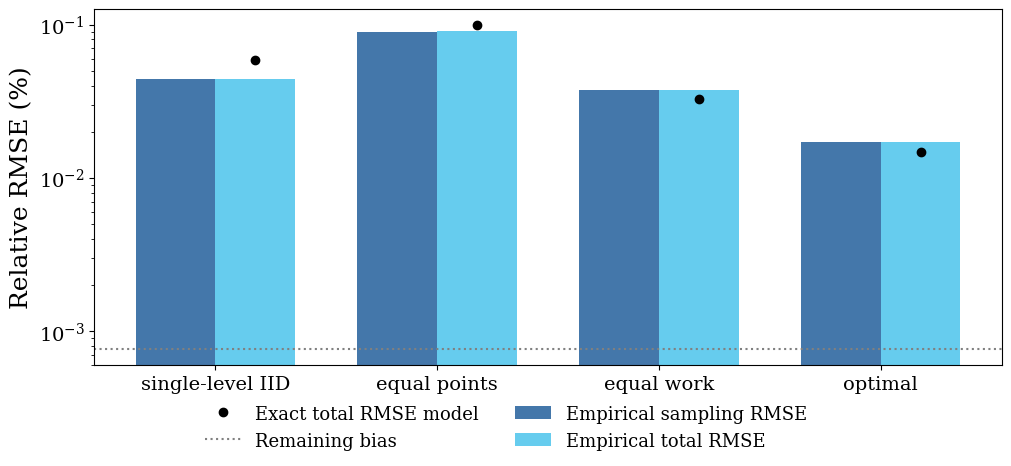

### Single level versus optimal MLMC at the same work budget

,Total panel work,Exact total RMSE (%),Empirical total RMSE (%),Seconds per estimate
design,,,,
single-level IID,33554432,0.0582958,0.0442765,0.0899831
pilot-allocated MLMC,33554128,0.0146574,0.0170699,0.34186


Both designs have the same maximum budget of **33,554,432 panel-work units**. The MLMC total includes its **188,416-unit allocation pilot**; small unused amounts come from rounding sample counts.

The exact variance-plus-bias calculation gives a **3.98-fold RMSE improvement**: MLMC RMSE is 25.1% of single-level RMSE, a **74.9% reduction**. The empirical comparison over **24 repetitions** gives a **2.59-fold improvement** (61.4% lower total RMSE). The empirical RMSE fluctuates with the repeated samples; the exact calculation uses known variances and bias for the allocation selected by this pilot.

However, MLMC uses **3.80 times as much clock time** in this run (0.342 versus 0.090 seconds per estimate, including the allocation pilot). **Improved RMSE at equal panel work does not imply improved clock-time efficiency.** The panel proxy omits costs of generating many material vectors, transformations, memory handling, and Python calls. Those costs matter for this small vectorized beam model.

In [6]:
def ml_estimate(counts, labels):
    return sum(values(ell, int(n), stream(*labels, int(ell))).mean()
               for ell,n in zip(levels, counts))

comparison = []
for j,kind in enumerate(['single-level IID', *allocations]):
    is_direct = kind=='single-level IID'
    counts = np.array([WORK_BUDGET//int(panels[-1])]) if is_direct else allocations[kind]
    pilot_work = PILOT_WORK if kind=='optimal' else 0
    started = time.perf_counter()
    estimates = np.array([values(L, int(counts[0]), stream(5,j,k), correction=False).mean()
                          if is_direct else ml_estimate(counts,(5,j,k))
                          for k in range(TRIALS)])
    final_seconds = (time.perf_counter()-started)/TRIALS
    pilot_seconds = PILOT_SECONDS if kind=='optimal' else 0.
    variance = variance_fine/counts[0] if is_direct else np.sum(V_exact/counts)
    final_work = int(counts[0]*panels[-1]) if is_direct else int(np.dot(counts,proxy_cost))
    comparison.append(dict(design=kind, final_work=final_work, pilot_work=pilot_work,
                           total_work=final_work+pilot_work,
                           unused_work=WORK_BUDGET-final_work-pilot_work,
                           sampling_RMSE=np.sqrt(np.mean((estimates-mu_fine)**2)),
                           total_RMSE=np.sqrt(np.mean((estimates-mu)**2)),
                           exact_total_RMSE=np.sqrt(variance+bias**2),
                           final_seconds=final_seconds,pilot_seconds=pilot_seconds,
                           total_seconds=final_seconds+pilot_seconds))
comparison = pd.DataFrame(comparison).set_index('design')
comparison['sampling_RMSE_percent'] = 100*comparison.sampling_RMSE/abs(mu_fine)
comparison['total_RMSE_percent'] = 100*comparison.total_RMSE/abs(mu)
comparison['exact_total_RMSE_percent'] = 100*comparison.exact_total_RMSE/abs(mu)
display(comparison[['sampling_RMSE_percent','total_RMSE_percent','exact_total_RMSE_percent']])
display(comparison[['final_work','pilot_work','total_work','unused_work']])
display(comparison[['final_seconds','pilot_seconds','total_seconds']])
fig, ax = plt.subplots(figsize=(10, 4.6), constrained_layout=True)
positions = np.arange(len(comparison))
ax.bar(positions-.18, comparison.sampling_RMSE_percent, width=.36, label='Empirical sampling RMSE')
ax.bar(positions+.18, comparison.total_RMSE_percent, width=.36, label='Empirical total RMSE')
ax.plot(positions+.18, comparison.exact_total_RMSE_percent, 'ko', label='Exact total RMSE model')
ax.axhline(100*bias/abs(mu), color='gray', linestyle=':', label='Remaining bias')
ax.set(xticks=positions, xticklabels=comparison.index, ylabel='Relative RMSE (%)', yscale='log')
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=2, fontsize=13)
plt.show()

# Read the accuracy/work comparison separately from the measured timing.
single = comparison.loc['single-level IID']
mlmc = comparison.loc['optimal']
exact_rmse_gain = single.exact_total_RMSE/mlmc.exact_total_RMSE
empirical_rmse_gain = single.total_RMSE/mlmc.total_RMSE
time_ratio = mlmc.total_seconds/single.total_seconds
same_work_comparison = comparison.loc[['single-level IID','optimal'],
    ['total_work','exact_total_RMSE_percent','total_RMSE_percent','total_seconds']].rename(
    index={'optimal':'pilot-allocated MLMC'},
    columns={'total_work':'Total panel work',
             'exact_total_RMSE_percent':'Exact total RMSE (%)',
             'total_RMSE_percent':'Empirical total RMSE (%)',
             'total_seconds':'Seconds per estimate'})
display(Markdown('### Single level versus optimal MLMC at the same work budget'))
display(same_work_comparison)
clock_comparison = (f'{time_ratio:.2f} times as much clock time' if time_ratio>=1
                    else f'{100*(1-time_ratio):.1f}% less clock time')
display(Markdown(
    f'Both designs have the same maximum budget of **{WORK_BUDGET:,} panel-work units**. '
    f'The MLMC total includes its **{PILOT_WORK:,}-unit allocation pilot**; '
    'small unused amounts come from rounding sample counts.\n\n'
    f'The exact variance-plus-bias calculation gives a **{exact_rmse_gain:.2f}-fold RMSE improvement**: '
    f'MLMC RMSE is {100/exact_rmse_gain:.1f}% of single-level RMSE, '
    f'a **{100*(1-1/exact_rmse_gain):.1f}% reduction**. '
    f'The empirical comparison over **{TRIALS} repetitions** gives a '
    f'**{empirical_rmse_gain:.2f}-fold improvement** '
    f'({100*(1-1/empirical_rmse_gain):.1f}% lower total RMSE). '
    'The empirical RMSE fluctuates with the repeated samples; the exact calculation '
    'uses known variances and bias for the allocation selected by this pilot.\n\n'
    f'However, MLMC uses **{clock_comparison}** in this run '
    f'({mlmc.total_seconds:.3f} versus {single.total_seconds:.3f} seconds per estimate, '
    'including the allocation pilot). '
    '**Improved RMSE at equal panel work does not imply improved clock-time efficiency.** '
    'The panel proxy omits costs of generating many material vectors, transformations, '
    'memory handling, and Python calls. Those costs matter for this small vectorized beam model.'
))


## 4. More samples do not remove approximation bias

For this uniformly loaded beam, exact integration over the material regions gives
\begin{align*}
P(\boldsymbol X)&=\sum_{j=1}^q a_j e^{-X_j}, &
a_j&=\frac{(1-(j-1)/q)^4-(1-j/q)^4}{8},\\
\rho&=\mathbb E(e^{-X_1})=\frac{e^{-a}-e^{-b}}{b-a}, &
\mu&=\rho/8.
\end{align*}
For a midpoint grid with $d$ panels, with $d$ a multiple of $q$,
$$
\mu_d=\rho\left(\frac18-\frac1{16d^2}\right),
\qquad b_L=\mu-\mu_{d_L}=\frac{\rho}{16d_L^2}.
$$
Thus **doubling the panels divides bias by four**. These are analytic references for this chosen beam/load, not general formulas for all beam models.

Relative to the limiting mean,
$$
\operatorname{MSE}(\widehat\mu)=b_L^2+\sum_{\ell=1}^L V_\ell/n_\ell.
$$
The first graph shows what refinement changes. The second keeps $L$ fixed and increases work: sampling error decreases, but total RMSE approaches the bias floor. The curves use exact variances to expose the distinction without another noisy experiment.

### Reading the bias table and plots

`exact_mean` is $\mu_d$ for that row's grid. `bias` is the known difference $\mu-\mu_d$. `bias_ratio_on_refinement` compares the previous grid's bias with the current one; its first entry is blank because there is no preceding grid. Values of four confirm second-order grid accuracy for this model.

Both plots use logarithmic axes. **Left:** move right by refining the grid; the bias falls. The vertical dotted line marks the fixed finest grid used in the earlier comparison. **Right:** keep that grid and increase a hypothetical work budget. The sampling-RMSE curve falls, while total RMSE approaches the horizontal bias line. Better allocation can reduce sampling error substantially even when the remaining bias limits total accuracy.


The right-hand curves evaluate the exact error model at large hypothetical work budgets; no samples are generated at those sizes. A finer grid has a smaller bias floor, so its eventual plateau can require a much larger budget to reach.

,panels,exact_mean,bias,bias_ratio_on_refinement
0,16,0.053936,0.00010555,NaN
1,32,0.0540152,2.63875e-05,4
2,64,0.0540349,6.59687e-06,4
3,128,0.0540399,1.64922e-06,4
4,256,0.0540411,4.12304e-07,4
5,512,0.0540414,1.03076e-07,4
6,1024,0.0540415,2.5769e-08,4
7,2048,0.0540415,6.44225e-09,4


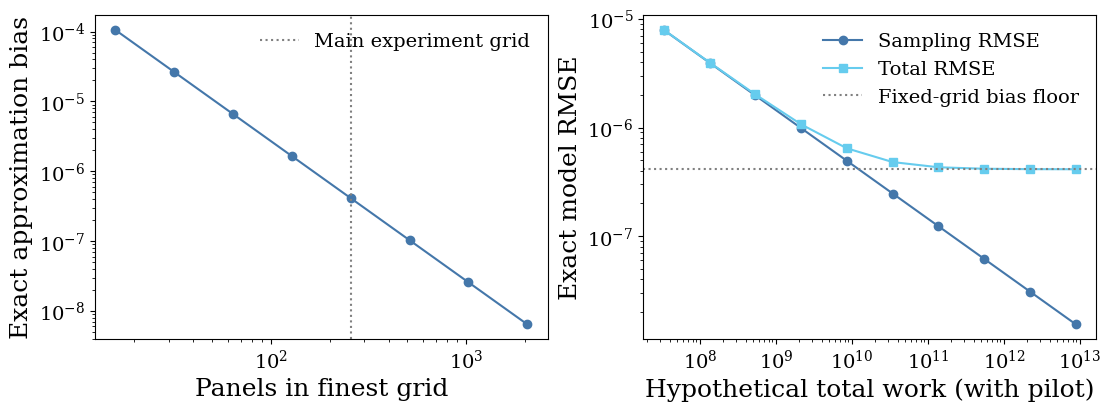

In [7]:
resolution = REGIONS*2**np.arange(8)
means = np.array([reference_moments(int(d))[0] for d in resolution])
biases = mu-means
rho, _ = compliance_moments()
np.testing.assert_allclose(biases, rho/(16*resolution**2), rtol=2e-9)
display(pd.DataFrame({'panels':resolution, 'exact_mean':means, 'bias':biases,
                      'bias_ratio_on_refinement':np.r_[np.nan, biases[:-1]/biases[1:]]}))
start_power = int(np.ceil(np.log2(max(WORK_BUDGET, 2*PILOT_WORK))))
work_grid = 2.**np.arange(start_power, start_power+19, 2)
sampling = np.array([np.sqrt(np.sum(V_exact/allocation(c-PILOT_WORK))) for c in work_grid])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].loglog(resolution, biases, 'o-')
axes[0].axvline(panels[-1], color='gray', linestyle=':', label='Main experiment grid')
axes[0].set(xlabel='Panels in finest grid', ylabel='Exact approximation bias')
axes[0].legend()
axes[1].loglog(work_grid, sampling, 'o-', label='Sampling RMSE')
axes[1].loglog(work_grid, np.sqrt(sampling**2+bias**2), 's-', label='Total RMSE')
axes[1].axhline(bias, color='gray', linestyle=':', label='Fixed-grid bias floor')
axes[1].set(xlabel='Hypothetical total work (with pilot)', ylabel='Exact model RMSE')
axes[1].legend()
plt.show()

## 5. Let QMCPy choose samples and levels

`BeamMultilevel` supplies the coarse/fine beam evaluations for the same `REGIONS` material parameters to QMCPy's native `CubMLMC`. QMCPy then chooses both sample counts and the finest grid using its bias/variance model. Levels start at one; the package's refinement levels start at zero.

The requested `rmse_tol` is a planning target. A single realized error need not lie below an RMSE target. We can independently check the selected grid's bias here because this example has an exact reference; a general PDE problem requires a justified bias assessment. The earlier fixed-grid comparisons isolate allocation from refinement.

### Reading the adaptive output

Each row is a fresh run with its stated **total RMSE target**. `estimate` is the realized estimate of the limiting mean; `realized_error` is its absolute error, not an RMSE over repeated runs. `known_grid_bias` checks the selected finest grid against the analytic limit. `count_based_RMSE` combines known variances and bias with the selected counts; because those counts depend on the data, it is a diagnostic rather than a repeated-run accuracy certificate.

The resource table reports the chosen finest grid, number of levels, total contribution count, total panel work, and measured seconds. The printed count arrays list levels 1 upward. QMCPy retains its adaptive samples in the estimate, so this run has no separate discarded pilot charge to add; `total_work` already counts all reported contributions. These adaptive runs may select different finest grids and should not be read as another fixed-grid, equal-budget comparison.


In [8]:
rows = []
for j,tolerance in enumerate([8e-5, 2e-5]):
    integrand = BeamMultilevel(qp.IIDStdUniform(REGIONS, seed=stream(6,j)), lower=LOWER, upper=UPPER)
    started = time.perf_counter()
    solution, data = qp.CubMLMC(integrand, rmse_tol=tolerance,
                                n_init=64, n_limit=2**22, levels_max=7).integrate()
    total_seconds = time.perf_counter()-started
    counts = np.asarray(data.n_level, dtype=int)
    selected_panels = REGIONS*2**(len(counts)-1)
    selected_mean, _ = reference_moments(selected_panels)
    exact_sampling_variance = sum(level_moments(ell)[1]/n
                                  for ell,n in enumerate(counts, start=1))
    adaptive_panels = REGIONS*2**np.arange(len(counts))
    adaptive_cost = adaptive_panels+np.r_[0,adaptive_panels[:-1]]
    rows.append(dict(requested_RMSE=tolerance, estimate=float(solution),
                     realized_error=abs(float(solution)-mu), finest_panels=selected_panels,
                     known_grid_bias=mu-selected_mean,
                     count_based_RMSE=np.sqrt((mu-selected_mean)**2+exact_sampling_variance),
                     level_count=len(counts),total_samples=int(counts.sum()),
                     total_work=int(np.dot(counts,adaptive_cost)),total_seconds=total_seconds))
    print(f'Target {tolerance:g}; contributions by level: {counts}')
adaptive_summary = pd.DataFrame(rows)
display(adaptive_summary[['requested_RMSE','estimate','realized_error','known_grid_bias','count_based_RMSE']])
display(adaptive_summary[['requested_RMSE','finest_panels','level_count','total_samples','total_work','total_seconds']])
print('The count-based RMSE is a plug-in diagnostic: adaptive counts depend on data, so this is not an exact repeated-run RMSE certificate')

Target 8e-05; contributions by level: [45047    64    64]
Target 2e-05; contributions by level: [650089    437    190]


,requested_RMSE,estimate,realized_error,known_grid_bias,count_based_RMSE
0,8e-05,0.0540656,2.4045e-05,6.59687e-06,5.40897e-05
1,2e-05,0.054031,1.05248e-05,6.59687e-06,1.56037e-05


,requested_RMSE,finest_panels,level_count,total_samples,total_work,total_seconds
0,8e-05,64,3,45175,729968,0.00937967
1,2e-05,64,3,650716,10440640,0.140306


The count-based RMSE is a plug-in diagnostic: adaptive counts depend on data, so this is not an exact repeated-run RMSE certificate


## Takeaways and sources

- Couple fine and coarse solves with the same physical material sample.
- Use independent sample sets across the reported level means.
- Compare contribution counts with the work they cost, including allocation pilots.
- Increase sample counts to reduce sampling error; refine the grid to reduce bias.

This intentionally small model has separable parameter dependence and an exact solution. A practical solver could exploit those properties. Here we retain explicit panel evaluations to make a transparent hierarchy; its measured speed comparisons do not predict those of a large PDE solver.

QMCPy supplies all random inputs, their uniform transformation, `CustomFun`, and the native adaptive MLMC algorithm. The course helper supplies the deterministic beam model and analytic checks. NumPy, pandas, Matplotlib, and `classlib.nbviz` support the experiments and figures.

Sources: [UM-Bridge beam description](https://um-bridge-benchmarks.readthedocs.io/en/docs/forward-benchmarks/muq-beam-propagation.html), [benchmark source](https://github.com/UM-Bridge/benchmarks/tree/main/benchmarks/muq-beam-propagation), [QMCPy UM-Bridge demo](https://github.com/QMCSoftware/QMCSoftware/blob/develop/demos/umbridge.ipynb), and the course's pinned QMCPy `CubMLMC` implementation. The material-region count, wider uncertainty, unit load, midpoint hierarchy, and exact reference calculations are classroom adaptations.

In [9]:
notebook_elapsed = time.perf_counter()-NOTEBOOK_START_TIME
notebook_minutes, notebook_seconds = divmod(notebook_elapsed, 60)
print('Total execution time for this notebook is '
      f'{int(notebook_minutes)} min {notebook_seconds:.1f} sec.')

Total execution time for this notebook is 0 min 20.7 sec.
